# 06 · Efficient: can the best model be made small and fast without losing trust or robustness? (Experiment 4)

**Teacher:** spelling-augmented HingBERT, seed 43 (notebook 05): 12 layers, 109.5 M parameters, 418 MB.

| Step | What it does | Expected saving |
|---|---|---|
| **1. Vocabulary trimming** | keep only the word pieces our tweets use (plus every single character, so unseen spellings can still be written out) | most of the 23 M-parameter embedding table |
| **2. Distillation 12 → 6 layers** | student starts from every second teacher layer and learns from the teacher's soft predictions plus the true labels | half the encoder; ~2× faster |
| **3. Dynamic int8 quantisation** | store and compute every Linear layer in 8-bit integers | ~4× smaller Linear layers |

**Targets (from the plan):** about **4× smaller**, at most **3 F1 points** lost, ECE after scaling about **0.05**, and a respelling drop about as small as the teacher's.

Each step is measured on its own, so we can see which one costs what. Ablation: the same 6-layer student trained **without** the teacher, to show whether distillation itself matters.

Code: `src/hinglish/efficient.py`. GPU needed only for section 3 (6 student runs, about 40 min on the M4 Pro; finished runs are skipped). Speed is measured on the **CPU at batch size 1**, which is how a single live prediction is served.

In [1]:
import sys, json
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, torch
from scipy.special import softmax
from sklearn.metrics import f1_score

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
FIG_DIR = ROOT / "results/figures"; FIG_DIR.mkdir(parents=True, exist_ok=True)
OUT = ROOT / "runs_efficient"; OUT.mkdir(exist_ok=True)
EVAL = OUT / "eval"; EVAL.mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

from transformers import AutoTokenizer, AutoModelForSequenceClassification
from hinglish.data import load_splits
from hinglish.robust import english_vocab, mine_variants, perturb, augment_train
from hinglish.train import make_loader, predict_logits, get_device
from hinglish.calibration import ece_score, fit_temperature, apply_temperature
from hinglish.efficient import (trimmed_vocab, trim_model, make_student, run_distill, DistillConfig,
                                quantize_int8, size_mb, cpu_latency_ms, cpu_logits)

S = load_splits(ROOT / "data/processed"); tr, te = S["train"], S["test"]
eng = english_vocab(tr); V = mine_variants(tr, eng)
T_DIR = ROOT / "runs_robust/aug/hingbert/seed43/model"
tok = AutoTokenizer.from_pretrained(T_DIR)
teacher = AutoModelForSequenceClassification.from_pretrained(T_DIR).eval()
device = get_device()
print("teacher:", round(sum(p.numel() for p in teacher.parameters()) / 1e6, 1), "M parameters | device for training:", device)

/Users/rahullalwani/Documents/IITMandi/Sem1/NLP/Project/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


W1116 20:41:43.325000 56196 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 201/201 [00:00<00:00, 8483.83it/s]

teacher: 109.5 M parameters | device for training: mps


## 1. Vocabulary trimming

Word pieces are collected from train, validation, the spelling-augmented train set and two rule-respelled copies of train. **Test tweets are never used.** Every single character (and its `##` continuation) is also kept, so any new spelling can still be split into pieces instead of becoming `[UNK]`.

In [2]:
if not (OUT / "student_init/config.json").exists():
    texts = [tr.text, S["val"].text, augment_train(tr, V, eng, share=1.0, seed=7).text] + \
            [perturb(tr, 1.0, "rule", V, eng, seed=s).text for s in (1, 2)]
    keep = trimmed_vocab(tok, texts)
    tm, ttok = trim_model(teacher, tok, keep, OUT / "teacher_trimmed")
    st = make_student(tm)
    st.save_pretrained(OUT / "student_init"); ttok.save_pretrained(OUT / "student_init")
ttok = AutoTokenizer.from_pretrained(OUT / "teacher_trimmed")
teacher_trim = AutoModelForSequenceClassification.from_pretrained(OUT / "teacher_trimmed").eval()
print(f"vocabulary: {len(tok):,} -> {len(ttok):,} word pieces ({len(ttok) / len(tok):.0%} kept)")
print(f"embedding table: {teacher.bert.embeddings.word_embeddings.weight.numel() / 1e6:.1f} M -> "
      f"{teacher_trim.bert.embeddings.word_embeddings.weight.numel() / 1e6:.1f} M parameters")

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 201/201 [00:00<00:00, 10882.62it/s]

vocabulary: 30,522 -> 13,130 word pieces (43% kept)
embedding table: 23.4 M -> 10.1 M parameters


In [3]:
TEST_SETS = {"clean": te}
for mode in ["natural", "rule"]:
    for p in [0.25, 0.5, 1.0]:
        TEST_SETS[f"{mode} {int(p * 100)}%"] = perturb(te, p, mode, V, eng, seed=2025)   # same sets as notebook 05
SETS = list(TEST_SETS)

rows = []
for k in ["clean", "natural 100%", "rule 100%"]:
    d = TEST_SETS[k]
    a, b = tok(list(d.text))["input_ids"], ttok(list(d.text))["input_ids"]
    rows.append({"test set": k,
                 "same word pieces": np.mean([tok.convert_ids_to_tokens(x) == ttok.convert_ids_to_tokens(y) for x, y in zip(a, b)]),
                 "[UNK] rate, full vocab": np.mean([i == tok.unk_token_id for x in a for i in x]),
                 "[UNK] rate, trimmed": np.mean([i == ttok.unk_token_id for x in b for i in x])})
display(pd.DataFrame(rows).set_index("test set").round(4))
print("Tweets with different pieces use a word piece never seen in train; it is split into smaller pieces instead.")

,same word pieces,"[UNK] rate, full vocab","[UNK] rate, trimmed"
test set,,,
clean,0.8493,0.0080,0.0079
natural 100%,0.8503,0.0077,0.0076
rule 100%,0.8513,0.0076,0.0076


Tweets with different pieces use a word piece never seen in train; it is split into smaller pieces instead.


## 2. Student initialisation

The student keeps the trimmed embeddings, the pooler, the classifier and teacher layers 0, 2, 4, 6, 8, 10.

In [4]:
student_init = AutoModelForSequenceClassification.from_pretrained(OUT / "student_init")
print("student:", student_init.config.num_hidden_layers, "layers,",
      round(sum(p.numel() for p in student_init.parameters()) / 1e6, 1), "M parameters")
del student_init

Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 105/105 [00:00<00:00, 10615.42it/s]

student: 6 layers, 53.6 M parameters


## 3. Train the students (GPU, ~40 min; skipped if done)

* **student_kd**: loss = 0.5 × KL(student ‖ teacher, temperature 2) + 0.5 × cross-entropy with the true label.
* **student_nokd** (ablation): cross-entropy only, the same as normal fine-tuning.

Both use the same spelling-augmented training tweets the teacher saw (a fresh draw per seed), learning rate 5e-5, 6 epochs, and the best epoch on **clean** validation. 3 seeds each.

In [5]:
teacher.to(device)
for kind, alpha in [("student_kd", 0.5), ("student_nokd", 0.0)]:
    for seed in [42, 43, 44]:
        splits = dict(S); splits["train"] = augment_train(tr, V, eng, seed=seed)
        tl = None
        if alpha > 0 and not (OUT / kind / f"seed{seed}/result.json").exists():
            tl = predict_logits(teacher, make_loader(tok, splits["train"].text, splits["train"].label_id, 128, 128, False), device)
        run_distill(kind, seed, OUT / "student_init", splits, tl, OUT, DistillConfig(alpha=alpha))
teacher.cpu()
pd.DataFrame([{**{k: r[k] for k in ["name", "seed", "best_epoch", "train_minutes"]},
               "val wF1": r["val"]["weighted_f1"], "test wF1": r["test"]["weighted_f1"]}
              for r in (json.loads(p.read_text()) for p in sorted(OUT.glob("student_*/seed*/result.json")))]).round(4)

[skip] student_kd seed42 already done
[skip] student_kd seed43 already done
[skip] student_kd seed44 already done


[skip] student_nokd seed42 already done
[skip] student_nokd seed43 already done
[skip] student_nokd seed44 already done


,name,seed,best_epoch,train_minutes,val wF1,test wF1
0,student_kd,42,1,5.9,0.6506,0.7239
1,student_kd,43,5,5.8,0.6521,0.7120
2,student_kd,44,1,5.8,0.6499,0.7208
3,student_nokd,42,1,5.8,0.6475,0.7241
4,student_nokd,43,1,20.3,0.6501,0.7115
5,student_nokd,44,1,5.9,0.6444,0.7223


## 4. Score every variant on clean + 6 respelled test sets

| Variant | Layers | Vocab | Weights | Seeds |
|---|---|---|---|---|
| Teacher | 12 | full | fp32 | 3 (from notebook 05) |
| Teacher, int8 | 12 | full | int8 | seed 43 |
| Teacher, trimmed vocab | 12 | trimmed | fp32 | seed 43 |
| Student, no teacher | 6 | trimmed | fp32 | 3 |
| Student, distilled | 6 | trimmed | fp32 | 3 |
| **Student, distilled, int8** | 6 | trimmed | int8 | 3 |

fp32 models are scored on the GPU and int8 models on the CPU, where int8 runs. Scores are cached in `runs_efficient/eval/`.

In [6]:
CFG_LEN, BS = 128, 128
def gpu_logits(model, tk, texts):
    m = model.to(device).eval()
    z = predict_logits(m, make_loader(tk, texts, np.zeros(len(texts), dtype=int), CFG_LEN, BS, False), device)
    model.cpu(); return z

def score_all(name, model, tk, int8=False):
    cache = EVAL / f"{name}.npz"
    if not cache.exists():
        f = (lambda t: cpu_logits(model, tk, t)) if int8 else (lambda t: gpu_logits(model, tk, t))
        z = {"val": f(list(S["val"].text))}
        z.update({k: f(list(d.text)) for k, d in TEST_SETS.items()})
        np.savez_compressed(cache, **z)
    z = np.load(cache); return {k: z[k] for k in z.files}

LOGITS, MODELS = {}, {}
# teacher: all 3 seeds were already scored on these exact test sets in notebook 05
for s in [42, 43, 44]:
    z = np.load(ROOT / f"runs_robust/eval/hingbert_aug_seed{s}.npz"); LOGITS[("teacher", s)] = {k: z[k] for k in z.files}
MODELS["teacher"] = (teacher, tok)

t_int8 = quantize_int8(teacher)
LOGITS[("teacher_int8", 43)] = score_all("teacher_int8_seed43", t_int8, tok, int8=True); MODELS["teacher_int8"] = (t_int8, tok)
LOGITS[("teacher_trim", 43)] = score_all("teacher_trim_seed43", teacher_trim, ttok); MODELS["teacher_trim"] = (teacher_trim, ttok)

for kind in ["student_nokd", "student_kd"]:
    for d in sorted((OUT / kind).glob("seed*/model")):
        s = int(d.parent.name[4:])
        m = AutoModelForSequenceClassification.from_pretrained(d).eval(); tk = AutoTokenizer.from_pretrained(d)
        LOGITS[(kind, s)] = score_all(f"{kind}_seed{s}", m, tk); MODELS[kind] = (m, tk)
        if kind == "student_kd":
            q = quantize_int8(m)
            LOGITS[("student_kd_int8", s)] = score_all(f"student_kd_int8_seed{s}", q, tk, int8=True); MODELS["student_kd_int8"] = (q, tk)
print(len(LOGITS), "variant × seed combinations scored")

/Users/rahullalwani/Documents/IITMandi/Sem1/NLP/Project/.venv/lib/python3.13/site-packages/torch/ao/nn/quantized/modules/utils.py:72: UserWarning: torch.quantize_per_tensor, torch.quantize_per_channel and other quantized tensor creation functions that produce tensors with dtype torch.quint8, torch.qint8, and torch.qint32 are deprecated and will be removed in a future PyTorch release. Please see https://github.com/pytorch/pytorch/issues/184982 for more information. (Triggered internally at /Users/runner/work/pytorch/pytorch/aten/src/ATen/quantized/Quantizer.cpp:116.)
  qweight = torch.quantize_per_tensor(


Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 105/105 [00:00<00:00, 18650.03it/s]

Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 105/105 [00:00<00:00, 15423.48it/s]

Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

... (5 outputs left out)

/Users/rahullalwani/Documents/IITMandi/Sem1/NLP/Project/.venv/lib/python3.13/site-packages/torch/_ops.py:1350: UserWarning: Currently, qnnpack incorrectly ignores reduce_range when it is set to true; this may change in a future release. (Triggered internally at /Users/runner/work/pytorch/pytorch/aten/src/ATen/native/quantized/cpu/qlinear_dynamic.cpp:251.)
  return self._op(*args, **kwargs)


Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 105/105 [00:00<00:00, 10557.15it/s]

14 variant × seed combinations scored


## 5. Size and CPU speed

Size = bytes of the saved weights. Speed = median CPU time per tweet at batch size 1 over 300 test tweets (4 threads, Apple M4 Pro). Weight-only quantities don't depend on the seed, so one model per variant is timed.

In [7]:
NAMES = {"teacher": "Teacher (12L, fp32)", "teacher_int8": "Teacher, int8", "teacher_trim": "Teacher, trimmed vocab",
         "student_nokd": "Student 6L, no teacher", "student_kd": "Student 6L, distilled", "student_kd_int8": "Student 6L, distilled, int8"}
ORDER = list(NAMES)
FP32_OF = {"teacher_int8": "teacher", "student_kd_int8": "student_kd"}   # int8 models hide their weights from .parameters()
eff = {}
for k in ORDER:
    m, tk = MODELS[k]
    pm, _ = MODELS[FP32_OF.get(k, k)]
    eff[k] = {"parameters (M)": sum(p.numel() for p in pm.parameters()) / 1e6,
              "size (MB)": size_mb(m), "CPU ms / tweet": cpu_latency_ms(m, tk, te.text, n=300)}
eff = pd.DataFrame(eff).T
eff["× smaller"] = eff.loc["teacher", "size (MB)"] / eff["size (MB)"]
eff["× faster"] = eff.loc["teacher", "CPU ms / tweet"] / eff["CPU ms / tweet"]
show = eff.copy(); show.index = [NAMES[k] for k in show.index]
display(show.round(2))

,parameters (M),size (MB),CPU ms / tweet,× smaller,× faster
"Teacher (12L, fp32)",109.48,417.73,16.38,1.00,1.00
"Teacher, int8",109.48,173.08,19.35,2.41,0.85
"Teacher, trimmed vocab",96.13,366.77,17.91,1.14,0.91
"Student 6L, no teacher",53.60,204.51,9.01,2.04,1.82
"Student 6L, distilled",53.60,204.51,8.56,2.04,1.91
"Student 6L, distilled, int8",53.60,81.34,9.64,5.14,1.70


## 6. Accuracy, robustness and trust of every variant

In [8]:
def aurc(logits, y):
    conf = softmax(logits, axis=1).max(1); order = np.argsort(-conf)
    err = (logits.argmax(1) != y)[order].astype(float)
    return float((np.cumsum(err) / np.arange(1, len(y) + 1)).mean())

y, yv = te.label_id.values, S["val"].label_id.values
rows = []
for (k, s), L in LOGITS.items():
    T = fit_temperature(L["val"], yv)
    r = {"variant": k, "seed": s, "T": T}
    for st in SETS:
        r[f"wF1 {st}"] = f1_score(y, L[st].argmax(1), average="weighted")
    r["ECE"] = ece_score(softmax(L["clean"], axis=1), y)
    r["ECE after T"] = ece_score(apply_temperature(L["clean"], T), y)
    r["AURC"] = aurc(L["clean"], y)
    r["ECE rule 100%"] = ece_score(softmax(L["rule 100%"], axis=1), y)
    rows.append(r)
res = pd.DataFrame(rows)
res["drop natural 100%"] = (res["wF1 natural 100%"] - res["wF1 clean"]) * 100
res["drop rule 100%"] = (res["wF1 rule 100%"] - res["wF1 clean"]) * 100

cols = ["wF1 clean", "drop natural 100%", "drop rule 100%", "ECE", "ECE after T", "T", "AURC"]
agg = res.groupby("variant")[cols].agg(["mean", "std"]).loc[ORDER]
final = pd.DataFrame({c: agg[(c, "mean")] for c in cols})
final["seeds"] = res.groupby("variant").seed.count().loc[ORDER]
final = eff[["size (MB)", "× smaller", "CPU ms / tweet", "× faster"]].join(final)
show = final.copy(); show.index = [NAMES[k] for k in show.index]
display(show.round(4))
print("F1 std over seeds:", {NAMES[k]: round(agg.loc[k, ("wF1 clean", "std")], 4) for k in ORDER if final.loc[k, "seeds"] > 1})

,size (MB),× smaller,CPU ms / tweet,× faster,wF1 clean,drop natural 100%,drop rule 100%,ECE,ECE after T,T,AURC,seeds
"Teacher (12L, fp32)",417.7254,1.0000,16.3789,1.0000,0.7258,-1.5543,-1.3191,0.0560,0.0492,1.4762,0.1352,3
"Teacher, int8",173.0848,2.4134,19.3457,0.8466,0.7214,-1.7657,-2.0579,0.0348,0.0475,1.2532,0.1428,1
"Teacher, trimmed vocab",366.7723,1.1389,17.9059,0.9147,0.7200,-2.3923,-1.6749,0.0792,0.0461,1.6333,0.1406,1
"Student 6L, no teacher",204.5077,2.0426,9.0074,1.8184,0.7193,-1.9788,-1.7426,0.0234,0.0677,1.3086,0.1492,3
"Student 6L, distilled",204.5077,2.0426,8.5616,1.9131,0.7189,-1.4414,-1.4960,0.0571,0.0607,1.6412,0.1463,3
"Student 6L, distilled, int8",81.3411,5.1355,9.6391,1.6992,0.7180,-1.7314,-1.8489,0.0467,0.0619,1.5661,0.1478,3


F1 std over seeds: {'Teacher (12L, fp32)': np.float64(0.0071), 'Student 6L, no teacher': np.float64(0.0068), 'Student 6L, distilled': np.float64(0.0062), 'Student 6L, distilled, int8': np.float64(0.006)}


### The research question: does efficiency cost accuracy, robustness or trust?

Each row compares a variant with the **teacher** (3-seed mean). Thresholds are the targets from the plan.

In [9]:
t = final.loc["teacher"]
chk = pd.DataFrame({
    "F1 lost (pts)": (t["wF1 clean"] - final["wF1 clean"]) * 100,
    "≤ 3 pts?": (t["wF1 clean"] - final["wF1 clean"]) * 100 <= 3,
    "× smaller": final["× smaller"], "≥ 4×?": final["× smaller"] >= 4,
    "rule drop vs teacher (pts)": final["drop rule 100%"] - t["drop rule 100%"],
    "ECE after T": final["ECE after T"], "≈ 0.05 (≤ 0.06)?": final["ECE after T"] <= 0.06,
    "AURC vs teacher": final["AURC"] - t["AURC"],
})
chk.index = [NAMES[k] for k in chk.index]
display(chk.round(4))

,F1 lost (pts),≤ 3 pts?,× smaller,≥ 4×?,rule drop vs teacher (pts),ECE after T,≈ 0.05 (≤ 0.06)?,AURC vs teacher
"Teacher (12L, fp32)",0.0000,True,1.0000,False,0.0000,0.0492,True,0.0000
"Teacher, int8",0.4470,True,2.4134,False,-0.7388,0.0475,True,0.0076
"Teacher, trimmed vocab",0.5817,True,1.1389,False,-0.3558,0.0461,True,0.0054
"Student 6L, no teacher",0.6521,True,2.0426,False,-0.4234,0.0677,False,0.0140
"Student 6L, distilled",0.6948,True,2.0426,False,-0.1769,0.0607,False,0.0111
"Student 6L, distilled, int8",0.7846,True,5.1355,True,-0.5298,0.0619,False,0.0126


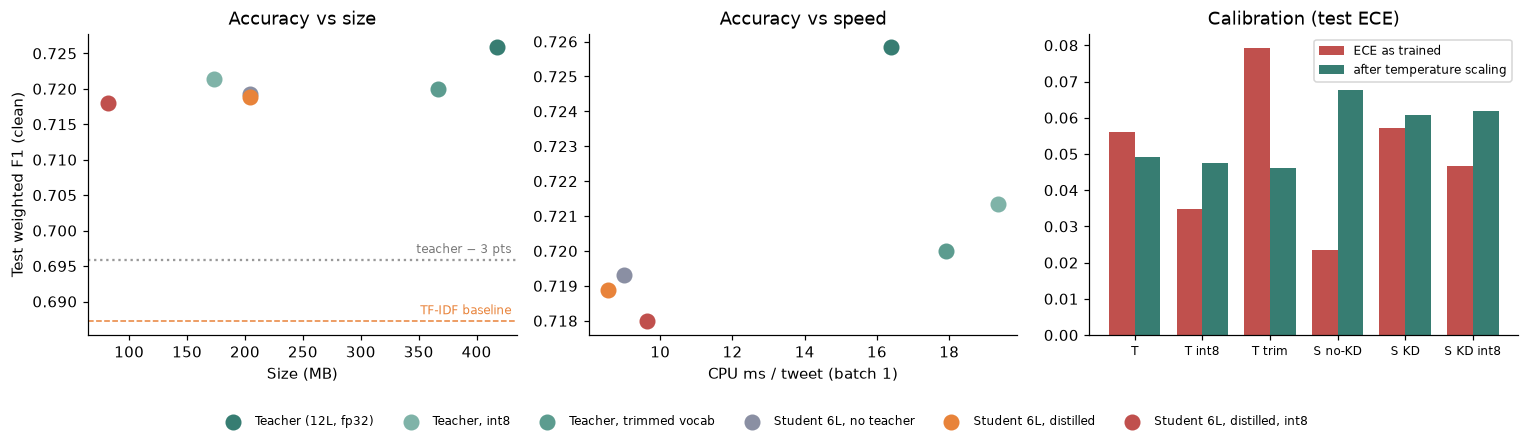

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
col = {"teacher": "#377D72", "teacher_int8": "#7FB3A8", "teacher_trim": "#5C9C8F",
       "student_nokd": "#8A8FA3", "student_kd": "#E8833A", "student_kd_int8": "#C0504D"}
for k in ORDER:
    r = final.loc[k]
    axes[0].scatter(r["size (MB)"], r["wF1 clean"], s=90, color=col[k], label=NAMES[k], zorder=3)
    axes[1].scatter(r["CPU ms / tweet"], r["wF1 clean"], s=90, color=col[k], zorder=3)
axes[0].axhline(final.loc["teacher", "wF1 clean"] - 0.03, ls=":", color="#999"); axes[0].text(430, final.loc["teacher", "wF1 clean"] - 0.029, "teacher − 3 pts", ha="right", fontsize=8, color="#777")
axes[0].axhline(0.6872, ls="--", color="#E8833A", lw=1); axes[0].text(430, 0.6882, "TF-IDF baseline", ha="right", fontsize=8, color="#E8833A")
axes[0].set_xlabel("Size (MB)"); axes[0].set_ylabel("Test weighted F1 (clean)"); axes[0].set_title("Accuracy vs size")
axes[1].set_xlabel("CPU ms / tweet (batch 1)"); axes[1].set_title("Accuracy vs speed")
x = np.arange(len(ORDER)); w = 0.38
axes[2].bar(x - w / 2, final["ECE"], w, color="#C0504D", label="ECE as trained")
axes[2].bar(x + w / 2, final["ECE after T"], w, color="#377D72", label="after temperature scaling")
axes[2].set_xticks(x, ["T", "T int8", "T trim", "S no-KD", "S KD", "S KD int8"], fontsize=8)
axes[2].set_title("Calibration (test ECE)"); axes[2].legend(fontsize=8)
h, l = axes[0].get_legend_handles_labels()
fig.legend(h, l, loc="lower center", ncol=6, fontsize=8, frameon=False)
plt.tight_layout(rect=(0, 0.08, 1, 1)); plt.savefig(FIG_DIR / "06_efficiency.png"); plt.show()

## 7. Save results

In [11]:
out = ROOT / "results"
res.to_csv(out / "06_efficiency_runs.csv", index=False)
final.rename(index=NAMES).to_csv(out / "06_efficiency_summary.csv")
chk.to_csv(out / "06_targets_check.csv")
print("saved:", *sorted(p.name for p in out.glob("06_*")), sep="\n  ")

saved:
  06_efficiency_runs.csv
  06_efficiency_summary.csv
  06_targets_check.csv


## Takeaways

**Final model: 6-layer distilled student, trimmed vocabulary, int8.** 81 MB instead of 418 MB (**5.1× smaller**), 9.6 instead of 16.4 CPU ms per tweet (**1.7× faster**), test wF1 **0.718** vs 0.726 (**−0.8 points**). It still beats every plain model from notebook 03, including plain HingBERT (0.713).

| Target | Result | Met? |
|---|---|---|
| ≥ 4× smaller | 5.1× | yes |
| ≤ 3 F1 points lost | 0.8 | yes |
| respelling drop close to the teacher's | rule −1.8 vs −1.3; natural −1.7 vs −1.6 | roughly (≈0.5 pt worse, within seed noise of ~0.5) |
| ECE after scaling ≈ 0.05 | 0.062 (teacher 0.049) | slightly missed |

**Answer to the research question:** making the model 5× smaller costs **a little of everything, but not much of anything**: −0.8 F1, about +0.5 points more drop under heavy respelling, +0.013 ECE after scaling, +0.013 AURC. Its *raw* confidence is actually more honest than the teacher's (ECE 0.047 vs 0.056).

**What each step costs:**
* **Vocabulary trimming** (30,522 → 13,130 pieces): −13 M parameters and only −0.6 F1. `[UNK]` does not increase even on respelled tweets, because every single character is kept.
* **Distillation 12 → 6 layers**: the biggest win: 2× smaller and 1.9× faster for −0.7 F1.
* **int8**: 2.5× smaller again for −0.1 F1, but **not faster on this Apple M4 Pro** (PyTorch's qnnpack int8 kernels are slower than its fp32 ones here; on x86 servers int8 is normally faster). The speed gain comes from distillation.

**Does the teacher's guidance matter?** Not for accuracy: students trained with and without the teacher score the same (0.719). Its value shows in **stability and robustness**: without the teacher, validation ECE climbs to 0.30–0.33 by epoch 6 (0.16 with it), and the distilled student loses less under respelling (natural −1.4 vs −2.0, rule −1.5 vs −1.7) and calibrates better after scaling (0.061 vs 0.068). Most of the student's accuracy comes from starting with the teacher's own layers.

**Possible improvements:** most students peaked at epoch 1, so a lower learning rate or fewer epochs could help, and temperature scaling could be fitted per variant on a held-out slice of train instead of the harder val set.